* Analysis by Mohan Giri


This notebook solves the consistency condition for the paper [System Energies for Pentaquark Family Using Thomas-Fermi Quark Model](https://www.overleaf.com/project/678c36234f23f43df415885b) using parameters in the table 1.
# Conclusions:
* Solved values are same within the computational uncertainties for most of the values of $\eta$.
* For $\eta = 4$, the solution from the mathematica and the python doesn't match.
    * - This discrepancy is due to different value of n1 and g1 values in the mathematica, and in the table. 
    * - In the [mathematica](https://github.com/evistcollaboration/Codes/blob/main/Pentaquark/ThreeRegion/Consistency_condition_cal/Mathematica%20Calculation%20of%20Consistency%20Conditions.nb), where consistency condition is solved, n1 = 3, and g1 = 4 is set. 
    * - However, in the [table 1](https://www.overleaf.com/project/678c36234f23f43df415885b) in the paper, n1 = 4 and g1 = 3 is set.


# Data from the table; Obtained Using Mathematica:

In [1]:
import pandas as pd

def table_from_paper():
    data = [
        [1, 0.27530, 0.96216, 0.39542, 1, 3, 1, 1, 1, 1],
        [2, 0.24858, 0.88262, 0.49745, 2, 3, 1, 2, 1, 2],
        [3, 0.22560, 0.85936, 0.39542, 3, 3, 3, 1, 3, 1],
        [4, 0.22047, 0.82371, 0.45567, 4, 3, 2, 2, 2, 2],
        [5, 0.21394, 0.82499, 0.39872, 5, 3, 5, 1, 5, 1],
        [6, 0.21321, 0.79469, 0.50524, 6, 3, 3, 2, 3, 2],
        [7, 0.20902, 0.81049, 0.40014, 7, 3, 7, 1, 7, 1],
        [8, 0.20906, 0.78413, 0.50623, 8, 3, 4, 2, 4, 2],
        [9, 0.20632, 0.80251, 0.40094, 9, 3, 9, 1, 9, 1],
        [10, 0.20660, 0.77785, 0.50682, 10, 3, 5, 2, 5, 2],
    ]

    columns = [
        r'$\eta$',
        r'$\beta_{12}/\bar{\beta}_{12}$',
        r'$\beta_{22}/\bar{\beta}_{22}$',
        r'$\gamma_{12}/\bar{\gamma}_{12}$',
        r'$N_1$', r'$g_1$', r'$N_2$', r'$g_2$', r'$\bar{N}_2$', r'$\bar{g}_2$'
    ]

    df = pd.DataFrame(data, columns=columns)
    return df

# Solutions obtained from mathematica
df = table_from_paper()
df

,$\eta$,$\beta_{12}/\bar{\beta}_{12}$,$\beta_{22}/\bar{\beta}_{22}$,$\gamma_{12}/\bar{\gamma}_{12}$,$N_1$,$g_1$,$N_2$,$g_2$,$\bar{N}_2$,$\bar{g}_2$
0,1,0.27530,0.96216,0.39542,1,3,1,1,1,1
1,2,0.24858,0.88262,0.49745,2,3,1,2,1,2
2,3,0.22560,0.85936,0.39542,3,3,3,1,3,1
3,4,0.22047,0.82371,0.45567,4,3,2,2,2,2
4,5,0.21394,0.82499,0.39872,5,3,5,1,5,1
5,6,0.21321,0.79469,0.50524,6,3,3,2,3,2
6,7,0.20902,0.81049,0.40014,7,3,7,1,7,1
7,8,0.20906,0.78413,0.50623,8,3,4,2,4,2
8,9,0.20632,0.80251,0.40094,9,3,9,1,9,1
9,10,0.20660,0.77785,0.50682,10,3,5,2,5,2


# Solving consistency condition Using Python:

In [5]:
class ConsistencyConditionSolverCaseI:
    '''Solves equation 11, 15, and 18 in paper to obtain the value of Q2bar, beta12_, beta22_, Q2, gamma12, and Q1 for case I with eta = 1 only.
    '''
    def __init__(self, n1, n2, n2bar, g1, g2, g2bar, alfa1, alfa2):
        self.n1 = n1
        self.n2 = n2
        self.n2bar = n2bar
        self.g1 = g1 
        self.g2 = g2
        self.g2bar = g2bar
        self.alfa1 = alfa1
        self.alfa2 = alfa2
        self.eta = (n1*g1 + n2*g2 + n2bar*g2bar) / 5
        self.theta = -6*self.eta / (5 * (5*self.eta - 1))

        self.solve_all()

    def three_function_solver(self):
        '''Solving the condition in the innermost region for case I
        '''
        from sympy import symbols, Eq, nsolve
        f, beta12_, beta22_ = symbols('f beta12_ beta22_', real=True)
        
        # Equation 11 in paper:
        f_1 = self.theta*(self.g1*beta12_**1.5 + self.g2*beta22_**1.5) / self.alfa2
        f_2 = self.theta * self.g2bar/beta12_ - 9*self.eta / (10 * (5*self.eta - 1) * beta12_) * ((self.n1*self.g1 - 1)*beta12_**1.5/self.n1 + self.g2*beta22_**1.5)
        f_3 = self.theta * self.g2bar/(beta22_ * self.alfa2) - 9*self.eta / (10 * (5*self.eta - 1) * self.alfa2 * beta22_) * ((self.n2*self.g2 - 1)*beta22_**1.5/self.n2 + self.g1*beta12_**1.5)

        eq1 = Eq(f, f_1)
        eq2 = Eq(f, f_2)
        eq3 = Eq(f, f_3)

        guess_f, guess_b12, guess_b22 = -1, 0.5, 0.5
        sol = nsolve((eq1, eq2, eq3), (f, beta12_, beta22_), (guess_f, guess_b12, guess_b22))
        self.Q2bar = float(sol[0])
        self.beta12_ =float(sol[1])
        self.beta22_ = float(sol[2])

    def two_function_solver(self):
        '''Solving the condition in the middle region for case I
        '''
        from sympy import symbols, Eq, nsolve
        f, gamma12 = symbols('f gamma12', real=True)

        # Equation 15 in paper:

        f_1 = 3*self.theta*((self.n1*self.g1 - 1)*gamma12**1.5/self.n1 + self.g2) / (4*gamma12)
        f_2 = 3*self.theta*((self.n2*self.g2 - 1)/self.n2 + (self.g1*gamma12**1.5)) / (4*self.alfa2)

        eq1 = Eq(f, f_1)
        eq2 = Eq(f, f_2)

        guess_f, guess_gamma12 = -1, 0.5
        sol = nsolve((eq1, eq2), (f, gamma12), (guess_f, guess_gamma12))

        self.Q2 =float(sol[0])
        self.gamma12 =float(sol[1])

    def Q1_solver(self):
        '''Solving the condition in the Outermost region for case I
        '''
        # Equation 18 in paper:
        self.Q1 = 3*self.theta*((self.n1*self.g1 -1)/(4*self.n1))

    def solve_all(self):
        print(f'Solving for eta = {self.eta}')
        self.three_function_solver()
        self.two_function_solver()
        self.Q1_solver()
        print(f"Q2bar = {self.Q2bar}")
        print(f"beta12_ = {self.beta12_}")
        print(f"beta22_ = {self.beta22_}")
        print(f"Q2 = {self.Q2}")
        print(f"gamma12 = {self.gamma12}")
        print(f"Q1 = {self.Q1}")

class ConsistencyConditionSolverCaseII:
    '''Solves equation 19, 20, and 18 in paper to obtain the value of Q2bar, beta12_, beta22_, Q2, gamma12, and Q1 for case II with eta > 1 only.
    '''
    def __init__(self, n1, n2, n2bar, g1, g2, g2bar, alfa1, alfa2_bar):
        self.n1 = n1
        self.n2 = n2
        self.n2bar = n2bar
        self.g1 = g1 
        self.g2 = g2
        self.g2bar = g2bar
        self.alfa1 = alfa1
        self.alfa2_bar = alfa2_bar
        self.eta = (n1*g1 + n2*g2 + n2bar*g2bar) / 5
        self.theta = -6*self.eta / (5 * (5*self.eta - 1))

        self.solve_all()

    def three_function_solver(self):
        '''Solving the condition in the innermost region for case II
        '''
        from sympy import symbols, Eq, nsolve
        f, beta12, beta2_2 = symbols('f beta12 beta2_2', real=True)

        # Equation 19 in paper:
        f_1 = self.theta / ( self.alfa2_bar * beta2_2)*(self.g1*beta12**1.5 + self.g2)
        f_2 = self.theta * self.g2bar * beta2_2**1.5/beta12 - 9*self.eta / (10 * (5*self.eta - 1) * beta12) * ((self.n1*self.g1 - 1)*beta12**1.5/self.n1 + self.g2)
        f_3 = self.theta * self.g2bar * beta2_2**1.5/( self.alfa2_bar) - 9*self.eta / (10 * (5*self.eta - 1) * self.alfa2_bar) * ((self.n2*self.g2 - 1)/self.n2 + self.g1*beta12**1.5) # here alfa2 = alfa2_bar

        eq1 = Eq(f, f_1)
        eq2 = Eq(f, f_2)
        eq3 = Eq(f, f_3)

        guess_f, guess_b12, guess_b22 = -1, 0.5, 0.5
        sol = nsolve((eq1, eq2, eq3), (f, beta12, beta2_2), (guess_f, guess_b12, guess_b22))
        self.Q2bar = float(sol[0])
        self.beta12 =float(sol[1])
        self.beta2_2 = float(sol[2])

    def two_function_solver(self):
        '''Solving the condition in the middle region for case II
        '''
        from sympy import symbols, Eq, nsolve
        f, gamma12_ = symbols('f gamma12_', real=True)

        # Equation 20 in paper:
        f_1 = self.theta/self.alfa2_bar *self.g1 * gamma12_**1.5
        f_2 = self.theta * self.g2bar / gamma12_ - 9*self.eta / (10 * (5*self.eta - 1) )* ((self.n1*self.g1 - 1)*gamma12_**0.5/self.n1)

        eq1 = Eq(f, f_1)
        eq2 = Eq(f, f_2)

        guess_f, guess_gamma12 = -1, 0.5
        sol = nsolve((eq1, eq2), (f, gamma12_), (guess_f, guess_gamma12))

        self.Q2 =float(sol[0])
        self.gamma12_ =float(sol[1])

    def Q1_solver(self):
        '''Solving the condition in the Outermost region for case I
        '''
        # Equation 18 in paper:
        self.Q1 = 3*self.theta*((self.n1*self.g1 -1)/(4*self.n1))

    def solve_all(self):
        print(f'\n Solving for eta = {self.eta}')
        self.three_function_solver()
        self.two_function_solver()
        self.Q1_solver()
        print(f"Q2bar = {self.Q2bar}")
        print(f"beta12 = {self.beta12}")
        print(f"beta2_2 = {self.beta2_2}")
        print(f"Q2 = {self.Q2}")
        print(f"gamma12_ = {self.gamma12_}")
        print(f"Q1 = {self.Q1}")

# Testing:
solver_caseI = ConsistencyConditionSolverCaseI(n1 = 1, n2 = 1, n2bar = 1, g1 = 3, g2 = 1, g2bar = 1, alfa1 = 1, alfa2 = 306/1553) # For eta = 1 or case I
solver_caseII = ConsistencyConditionSolverCaseII(n1 = 2, n2 = 1, n2bar = 1, g1 = 3, g2 = 2, g2bar = 2, alfa1 = 1, alfa2_bar = 306/1553) # For eta >1 or case II


Solving for eta = 1.0
Q2bar = -2.096875684166771
beta12_ = 0.27534512780775333
beta22_ = 0.9621499258086972
Q2 = -0.8519415145594924
gamma12 = 0.39546129699367755
Q1 = -0.44999999999999996

 Solving for eta = 2.0
Q2bar = -3.636976669156518
beta12 = 0.24862021383419958
beta2_2 = 0.8826216561167366
Q2 = -1.4247026436825498
gamma12_ = 0.49749586563926185
Q1 = -0.5


## Comparison of Solutions using Mathematica and Python:

from table: 1.0, From calculation: 1.0
Solving for eta = 1.0
Q2bar = -2.096875684166771
beta12_ = 0.27534512780775333
beta22_ = 0.9621499258086972
Q2 = -0.8519415145594924
gamma12 = 0.39546129699367755
Q1 = -0.44999999999999996
from table: 2.0, From calculation: 2.0

 Solving for eta = 2.0
Q2bar = -3.636976669156518
beta12 = 0.24862021383419958
beta2_2 = 0.8826216561167366
Q2 = -1.4247026436825498
gamma12_ = 0.49749586563926185
Q1 = -0.5
from table: 3.0, From calculation: 3.0

 Solving for eta = 3.0
Q2bar = -2.006903172097429
beta12 = 0.22563704978261456
beta2_2 = 0.8593673347656394
Q2 = -0.9736474452108485
gamma12_ = 0.39546129699367755
Q1 = -0.5142857142857142
from table: 4.0, From calculation: 4.0

 Solving for eta = 4.0
Q2bar = -3.6342197427973604
beta12 = 0.2217449904729763
beta2_2 = 0.8161134387565968
Q2 = -1.3735124322903354
gamma12_ = 0.5033257116500758
Q1 = -0.5210526315789474
from table: 5.0, From calculation: 5.0

 Solving for eta = 5.0
Q2bar = -1.9946052807547943
beta12 = 0

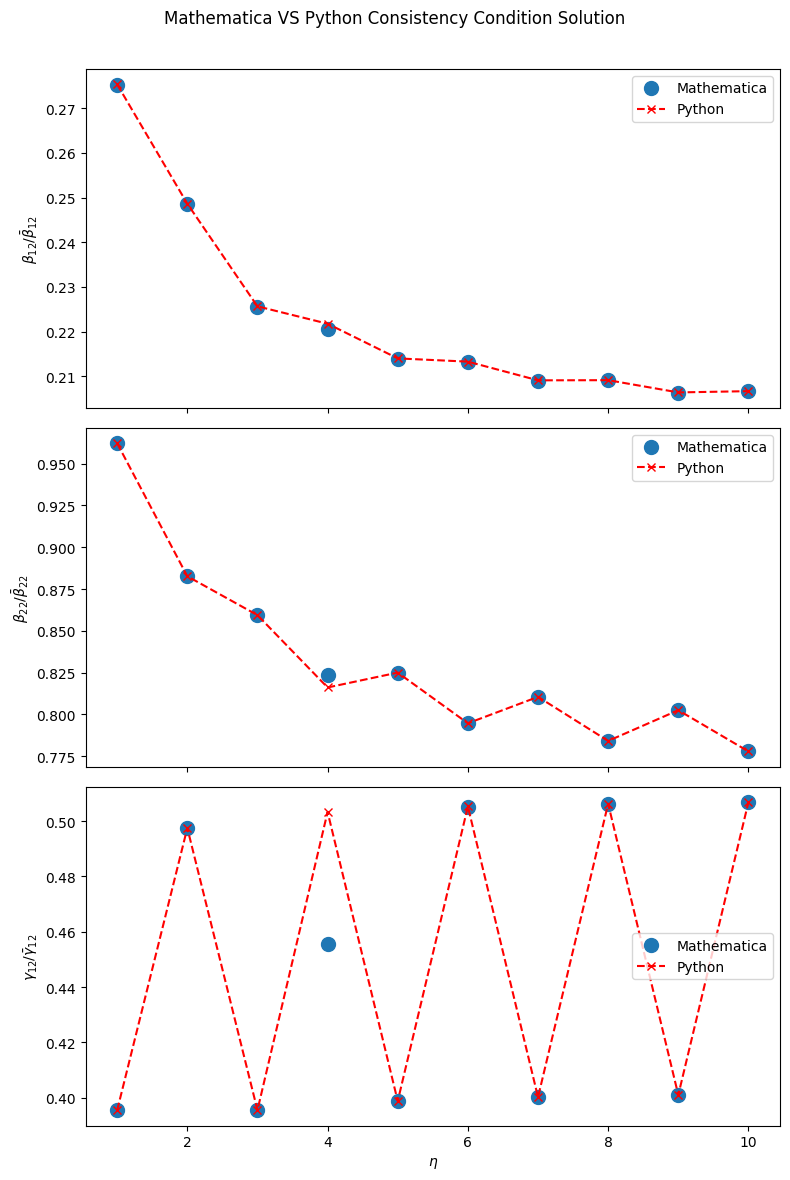

In [8]:
import matplotlib.pyplot as plt

def run_solvers_from_df(df):
    results = []

    for i in range(df.shape[0]):
        # Extract values from dataframe
        eta_val = df.iloc[i][r'$\eta$']
        n1 = df.iloc[i][r'$N_1$']
        g1 = df.iloc[i][r'$g_1$']
        n2 = df.iloc[i][r'$N_2$']
        g2 = df.iloc[i][r'$g_2$']
        n2bar = df.iloc[i][r'$\bar{N}_2$']
        g2bar = df.iloc[i][r'$\bar{g}_2$']
        eta = (n1 * g1 + n2 * g2 + n2bar * g2bar)/5
        print(f'from table: {eta_val}, From calculation: {eta}')

        alfa1 = 1
        alfa2 = 306/1553  # same constant you used in example

        # Choose solver based on your rule
        if eta_val == 1:
            solver = ConsistencyConditionSolverCaseI(
                n1, n2, n2bar, g1, g2, g2bar, alfa1, alfa2
            )
        else:
            solver = ConsistencyConditionSolverCaseII(
                n1, n2, n2bar, g1, g2, g2bar, alfa1, alfa2
            )

        # Collect results
        results.append({
            r'$\eta$': eta_val,
            'Q1': solver.Q1,
            'Q2': solver.Q2,
            'Q2bar': solver.Q2bar,
            'beta12': getattr(solver, 'beta12', getattr(solver, 'beta12_', None)),
            'beta22': getattr(solver, 'beta22_', getattr(solver, 'beta2_2', None)),
            'gamma12': getattr(solver, 'gamma12', getattr(solver, 'gamma12_', None)),
        })

    return pd.DataFrame(results)

# Run solver and get computed results
computed_df = run_solvers_from_df(df)

# Now create a combined dataframe with original and computed values side by side

# List of parameters to compare
params = ['beta12', 'beta22', 'gamma12']

combined_data = {r'$\eta$': df[r'$\eta$']}  # start with eta

for p in params:
    # original column names assumed to be in df
    # for example, original gamma12 column: r'$\gamma_{12}/\bar{\gamma}_{12}$' (you might need to adjust)
    # Let's guess mapping of original column names in df

    if p == 'gamma12':
        orig_col = r'$\gamma_{12}/\bar{\gamma}_{12}$'
    elif p == 'beta22':
        orig_col = r'$\beta_{22}/\bar{\beta}_{22}$'
    elif p == 'beta12':
        orig_col = r'$\beta_{12}/\bar{\beta}_{12}$'

    combined_data[f'{p}_Math'] = df[orig_col]
    combined_data[f'{p}_Pyth'] = computed_df[p]

combined_df = pd.DataFrame(combined_data)

# Now plotting all parameters for comparison
fig, axs = plt.subplots(len(params), 1, figsize=(8, 4*len(params)), sharex=True)
ylabels = [r'$\beta_{12}/\bar{\beta}_{12}$', r'$\beta_{22}/\bar{\beta}_{22}$', r'$\gamma_{12}/\bar{\gamma}_{12}$']
for i, p in enumerate(params):
    ax = axs[i] if len(params) > 1 else axs
    ax.plot(combined_df[r'$\eta$'], combined_df[f'{p}_Math'], 'o', label='Mathematica', markersize = 10)
    ax.plot(combined_df[r'$\eta$'], combined_df[f'{p}_Pyth'], 'rx--', label='Python')
    ax.set_ylabel(ylabels[i])
    #ax.grid(True)
    ax.legend()

axs[-1].set_xlabel(r'$\eta$')
plt.suptitle('Mathematica VS Python Consistency Condition Solution')
plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.savefig('consistency_solution_comparison.pdf')
plt.show()

In [4]:
combined_df

,$\eta$,beta12_Math,beta12_Pyth,beta22_Math,beta22_Pyth,gamma12_Math,gamma12_Pyth
0,1,0.27530,0.275345,0.96216,0.962150,0.39542,0.395461
1,2,0.24858,0.248620,0.88262,0.882622,0.49745,0.497496
2,3,0.22560,0.225637,0.85936,0.859367,0.39542,0.395461
3,4,0.22047,0.221745,0.82371,0.816113,0.45567,0.503326
4,5,0.21394,0.213978,0.82499,0.825001,0.39872,0.398759
5,6,0.21321,0.213252,0.79469,0.794695,0.50524,0.505289
6,7,0.20902,0.209064,0.81049,0.810505,0.40014,0.400183
7,8,0.20906,0.209100,0.78413,0.784141,0.50623,0.506274
8,9,0.20632,0.206359,0.80251,0.802518,0.40094,0.400977
9,10,0.20660,0.206640,0.77785,0.777859,0.50682,0.506867


## Verifying Mathematica result for $\eta = 4$ using same value in mathematica, different from the table:

In [7]:
ConsistencyConditionSolverCaseII(n1 = 3, n2 = 2, n2bar = 2, g1 = 4, g2 = 2, g2bar = 2, alfa1 = 1, alfa2_bar = 306/1553) # For eta >1 or case II


 Solving for eta = 4.0
Q2bar = -3.75776590304144
beta12 = 0.22050859095233957
beta2_2 = 0.8237191446374532
Q2 = -1.577727467402719
gamma12_ = 0.45571104323646916
Q1 = -0.6947368421052631


### Result: same within the computational uncertainty.

# Recommendation:
- Consult with Dr. Baral to confirm what value of n1 and g1 should be used for $\eta = 4$?